# Reti Generative Avversarie (GAN)

Una GAN è composta da due reti neurali che giocano a un **gioco minimax**:

- **Generatore G**: riceve rumore casuale $z \sim \mathcal{N}(0,1)$ e produce immagini false.
- **Discriminatore D**: riceve un'immagine (reale o falsa) e predice la probabilità che sia reale.

L'obiettivo è:

$$\min_G \max_D \; \mathbb{E}[\log D(x)] + \mathbb{E}[\log(1 - D(G(z)))]$$

Il generatore migliora finché il discriminatore non riesce più a distinguere reale da falso.

In [6]:
import torch

import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt

from torchvision import datasets, transforms

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(device)

cuda


#### Preparazione del dataset

CIFAR-10 contiene 60.000 immagini 32x32 RGB in 10 classi:
`airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck`

In [7]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # media, varianza
])

train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

batch_size = 32 # modificandolo modifichiamo le prestazioni della rete

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True) 
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck') # classi del dataset segnate per comodità

### Visualizzare esempi di immagini nel training:
# images, labels_batch = next(dataiter)

# fig, axes = plt.subplots(1, min(8, batch_size), figsize=(16, 2))
# for i in range(min(8, batch_size)):
#     img = images[i].cpu().numpy()
#     img = (img + 1) / 2  # Rescale from [-1,1] to [0,1]
#     img = img.transpose(1, 2, 0)
#     axes[i].imshow(img)
#     axes[i].set_title(f"Class: {classes[labels_batch[i]]}")
#     axes[i].axis('off')
# plt.tight_layout()
# plt.show()

Files already downloaded and verified


/home/giuseppe/Documents/Unipr/AppuntiUnipr/Python/.venv/lib/python3.12/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Files already downloaded and verified


### Due reti: il generatore e il discriminatore

#### Architettura del Generatore

Il generatore trasforma un vettore di rumore $z \in \mathbb{R}^{N}$ in un'immagine $32 \times 32 \times 3$.

#### Architettura del Discriminatore

Il discriminatore è un classificatore binario: **reale (1) vs. falsa (0)**.

In [8]:
class Generator(nn.Module):
    def __init__(self, noise_dim, n_classes, img_dim): # n_classes è il numero di classi del dataset, img_dim è la dimensione dell'immagine (3x32x32)
        super().__init__()
        self.img_channels = img_dim[0]
        self.img_size = img_dim[1]
        self.noise_dim = noise_dim
        self.label_emb = nn.Embedding(n_classes, n_classes)
        
        # Reshape: (noise_dim + n_classes) -> (noise_dim + n_classes, 1, 1)
        # ConvTranspose2d espande: (noise_dim + n_classes, 1, 1) -> (256, 4, 4) -> (512, 8, 8) -> (256, 16, 16) -> (3, 32, 32)
        self.model = nn.Sequential(

            nn.Linear(noise_dim + n_classes, 256), # layer fully connected
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, self.img_channels * self.img_size * self.img_size),
            nn.Tanh()
        
            # ## proviamo a migliorare l'architettura del generatore
            # # (512, 4, 4) to (256, 8, 8)
            # nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1), # stride: di quanto sposto il filtro surante la convoluzione (di default è 1 pixel) [ fa uno, salta uno e fa un altro]
            # nn.BatchNorm2d(256), # normalizzazione per migliorare la stabilità del training
            # nn.ReLU(),
            # # (256, 8, 8) to (128, 16, 16)
            # nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            # nn.BatchNorm2d(128),
            # nn.ReLU(),
            # # (128, 16, 16) to (3, 32, 32)
            # nn.ConvTranspose2d(128, 3, kernel_size=4, stride=2, padding=1),
            # nn.BatchNorm2d(3),
            # nn.Tanh() # output in [-1, 1], coerente con la normalizzazione del dataset
        )  

    def forward(self, noise, labels):
        c = self.label_emb(labels) # creo un embediing per questa etichetta
        x = torch.cat([noise, c], dim=1) 
        out = self.model(x)
        out = out.view(-1, self.img_channels, self.img_size, self.img_size) # prendo l'output e lo faccio assomigliare a un'immagine 
        return out

class Discriminator(nn.Module): # stessa strategi a del generatore, ma in questo caso prendo un'immagine e una classe e devo dire se è reale o fake
    def __init__(self, img_dim, n_classes):
        super().__init__()
        self.img_channels = img_dim[0]
        self.img_size = img_dim[1]

        self.label_emb = nn.Embedding(n_classes, n_classes) # gli diamo l'immagine e la classe e lui deve dire se è reale o fake, quindi anche qui abbiamo un embedding per la classe


        self.model = nn.Sequential( 
            nn.Linear(self.img_channels * self.img_size * self.img_size + n_classes, 128), # layer fully connected
            nn.LeakyReLU(0.2), # leakyrelu è una variante della relu che permette di avere un gradiente diverso da 0 anche per i valori negativi
            nn.Linear(128, 1), # il layer finale è 128, 1 perchè 1 si accende se è reale, 0 se è fake
            nn.Sigmoid()

            # ## proviamo a migliorare l'architettura del discriminatore
            # # (3, 32, 32) to (64, 16, 16)
            # nn.Conv2d(3, 64, kernel_size=4, stride=2, padding=1), # stride: di quanto sposto il filtro surante la convoluzione (di default è 1 pixel) [ fa uno, salta uno e fa un altro]
            # nn.LeakyReLU(0.2),          
            # # (64, 16, 16) to (128, 8, 8)
            # nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            # nn.BatchNorm2d(128),
            # nn.LeakyReLU(0.2),          
            # # (128, 8, 8) to (256, 4, 4)
            # nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            # nn.BatchNorm2d(256),
            # nn.LeakyReLU(0.2),
            # # classificatore finale:
            # nn.Flatten(), # appiattisce l'output in un vettore
            # nn.Linear(256 * 4 * 4, 1), # il layer finale
            # nn.Sigmoid()
        )

    def forward(self, img, labels):
        c = self.label_emb(labels) # condizionamento, mettiamo le label nell'embedding
        x = torch.cat([img, c], dim=1)
        return self.model(x)

generator = Generator(noise_dim=10, n_classes=10, img_dim=(3, 32, 32)).to(device) # la dimensione del rumore è importante: con 10 non imparerà molto, se abbiamo tempo possiamo mettere un numero molto più alto
discriminator = Discriminator(img_dim=(3, 32, 32), n_classes=10).to(device)

print(generator) # in output: 3072 con il calcolo di 3x32x32, è la dimensione dell'immagine che deve essere generata. si potevano mettera altri layyer in mezzo visto che 3072 è una dimensione grande
print(discriminator)

Generator(
  (label_emb): Embedding(10, 10)
  (model): Sequential(
    (0): Linear(in_features=20, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=3072, bias=True)
    (5): Tanh()
  )
)
Discriminator(
  (label_emb): Embedding(10, 10)
  (model): Sequential(
    (0): Linear(in_features=3082, out_features=128, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=128, out_features=1, bias=True)
    (3): Sigmoid()
  )
)


### Iperparametri, funzione di loss e ottimizzatore

### Loss GAN standard (Binary Cross-Entropy)

$$
\mathbb{E}_x[\log D(x)] + \mathbb{E}_z[\log(1 - D(G(z)))]
$$

- Discriminatore: massimizza $\log D(x) + \log(1 - D(G(z)))$
- Generatore: massimizza $\log D(G(z))$ (equivalente a minimizzare $\log(1 - D(G(z))))$

In [9]:
# Hyperparameters
num_epochs = 5
learning_rate = 0.002

criterion = nn.BCELoss()

optim_G = optim.Adam(generator.parameters(), lr=learning_rate) # adam usa un metodo adattivo per ridurre instabilità nell'addestramento, è più efficiente di SGD
optim_D = optim.Adam(discriminator.parameters(), lr=learning_rate)

#### Addestramento avversario

A ogni iterazione:
1. **Addestra D** su batch di immagini reali (label = 1) e false (label = 0)
2. **Addestra G** cercando di ingannare D (label = 1 per le immagini generate)

Attenzione: **non aggiornare D** durante il passo di G, e viceversa.

In [10]:
noise_dim = 10 
n_classes = 10

for epoch in range(num_epochs):
    for imgs, labels in train_loader:
        
        batch_size = imgs.size(0) # potremmo già saperlo, ma per sicurezza lo prendo nella prima dimensione dell'immagine
        imgs, labels = imgs.to(device), labels.to(device) # le metto sul deviice (se c'è)
        
        imgs_flat = imgs.view(batch_size, -1)  # appiattisco le immagini perchè non abbiamo una rete convoluzionale

        # Real and fake labels
        real = torch.ones(batch_size, 1, device=device) # la rete reale vale 1 per ogni label del batch (vettore di 32 uni)
        fake = torch.zeros(batch_size, 1, device=device) # la rete fake vale 0 per ogni label del batch (vettore di 32 zeri)
        
        # Train Discriminator # sia con immagini reali che con quelle fake
        # Generiamo le immagini fake:
        z = torch.randn(batch_size, noise_dim, device=device) # genero rumore gaussiano
        gen_labels = torch.randint(0, n_classes, (batch_size,), device=device) # le label sono da 0 al numero di classi, chiediamo di generare uno per ogni classe con l'embedding deciso all'inizio
        fake_imgs = generator(z, gen_labels) # immagini generate --- uso G
        fake_imgs_flat = fake_imgs.view(batch_size, -1) 

        # uso D su immagini reali:
        real_loss = criterion(discriminator(imgs_flat, labels), real) # prendo le immagini reali, le etichette reali e dico che devono essere reali (1)
        
        # uso D su immagini generate:
        fake_loss = criterion(discriminator(fake_imgs_flat.detach(), gen_labels), fake) # prendo le immagini fake, le etichette fake e dico che devono essere fake (0). detach serve a staccare il gradiente del generatore, altrimenti quando aggiorno il discriminatore aggiorno anche il generatore e non vogliamo questo
        
        d_loss = real_loss + fake_loss # calcolo la loss totale del discriminatore

        optim_D.zero_grad() 
        d_loss.backward()  # propago all'indietro le due loss
        optim_D.step()

        # Train Generator # dobbiamo prendere altro rumore gaussiano e le label, 
        z = torch.randn(batch_size, noise_dim, device=device) # dobbiamo prendere altro rumore gaussiano
        gen_labels = torch.randint(0, n_classes, (batch_size,), device=device) # dobbiamo prendere le label
        
        fake_imgs = generator(z, gen_labels) # usiamo G per generare immagini fake
        fake_imgs_flat = fake_imgs.view(batch_size, -1) # appiattisco le immagini fake per usarle nel discriminatore
        g_loss = criterion( 
            discriminator(fake_imgs_flat, gen_labels), # do al discriminatore le immagini fake e le label
            real # e dico che devono essere reali (1), perchè vogliamo che il generatore inganni il discriminatore
        ) 

        optim_G.zero_grad()
        g_loss.backward() # propago all'indietro la loss del generatore, il generatore diventerà sempre migliore man mano che il discriminatore sbaglia
        optim_G.step()

    # il discriminatore deve essere bravo quindi propaghiamo l'errore al generatore per dirgli "hai ancora un errore alto"

    print(f"Epoch {epoch + 1}/{num_epochs} | D Loss: {d_loss.item():.4f} | G Loss: {g_loss.item():.4f}")

    # in output: 
    # il D è troppo bravo (molto basso), G non impara a generare (molto alto). ci dovrebbe essere equilibrio tra i due, se D è troppo bravo G non impara, se G è troppo bravo D non impara. è importante che ci sia un equilibrio tra i due per farli migliorare entrambi.
    # possiamo aumentare lo spazio latente (batch_size), ma andrebbe cambiato anche nell'architettura: se è più grande ha più spazio per modificare le immagini e quindi può imparare a generare immagini più complesse
    # possiamo inserire un manual seed per la generazione di numeri casuali, in questo modo possiamo vedere sempre le stesse immagini generate e vedere se migliorano nel tempo

Epoch 1/5 | D Loss: 0.0015 | G Loss: 100.0000


KeyboardInterrupt: 

#### Generazione di immagini

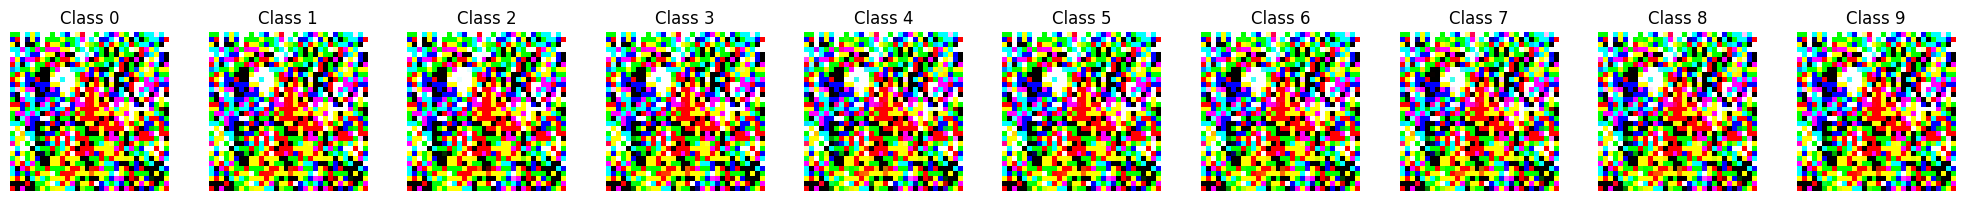

In [11]:
# Generate some images
noise = torch.randn(10, 10)  # 10 random noise vectors
labels = torch.arange(10)  # 10 different labels
noise = noise.to('cpu')
labels = labels.to('cpu')
n_classes_to_show = 10

# Visualize generated images
with torch.no_grad():
    generated_imgs = generator(noise, labels)

fig, axes = plt.subplots(1, n_classes_to_show, figsize=(2*n_classes_to_show, 2))
for i, ax in enumerate(axes):
    img = generated_imgs[i].cpu().numpy()
    img = (img + 1) / 2  # Rescale from [-1,1] to [0,1]
    img = img.transpose(1, 2, 0)
    ax.imshow(img)
    ax.set_title(f"Class {i}")
    ax.axis('off')
plt.tight_layout()
plt.show()

### Migliorie al modello

Effettuare un fine-tuning degli iperparametri.

Dopodiché ragionare su una nuova architettura di G e D che possa garantire performance migliori.

In [12]:

# Discriminatore, come possiamo modificare l'architettura per renderlo più efficiente?
# nn.Conv2d, nn.MaxPool2d, nn.LeakyReLU, nn.Linear, nn.Sigmoid 

# Generator, come possiamo modificare l'architettura per renderlo più efficiente?
# nn.ConvTranspose2d, nn.ConvTranspose2d nn.ReLU, nn.Linear, nn.Tanh 
# ConvTranspose2d da una dimensione piccola dell'imput vanno a darmiuna dimensione sempre più grande usando dei filtri convolutivi, quindi al contrario (deconvolutional)
